# Fase 4: Modelado (CRISP-DM) — Notebook de Experimentación y Validación

**Proyecto:** Sistema Predictivo de Riesgo Crediticio (*Home Credit Default Risk*) · **Grupo 12 — UNMSM**  
**Rúbricas cubiertas:**  
- **4.1 Selección de técnicas de modelado:** Progresión ordenada de menor a mayor complejidad (Niveles 0 a 4: `DummyClassifier`, `LogisticRegression`, `RandomForest` ref., `XGBoost`, `LightGBM`), justificada con **casos reales bancarios/Fintech** y literatura en revistas **Q1, Q2 y Q3** (Scopus/WoS).
- **4.2 Plan de pruebas:** Matriz formal de casos de prueba (`TC-01` a `TC-07`), aislamiento muestral anti-leakage y validación cruzada estratificada de 5 pliegues (`5-Fold StratifiedKFold`).
- **4.3 Construcción y ajuste de parámetros:** Estudio de sensibilidad, regularización estructural e importancia de variables por ganancia (*Gain*).
- **4.4 Evaluación técnica, calibración e inferencia:** Comparativa integral, Curva de Calibración / Brier Score, pruebas de significancia pareadas ($t=23.80, p < 0.001$) y prototipo `FastAPI`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path('..').resolve()
OUT_DIR = Path('salida_fase4')
TABLAS_DIR = OUT_DIR / 'tablas'
FIG_DIR = Path('figuras')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
print('Directorio de artefactos:', OUT_DIR.resolve())

Directorio de artefactos: D:\Universidad\Ciclos\8° CICLO\MINERÍA DE DATOS\PROYECTO\Sistema-Predictivo_Home-Credit\04-modelado\salida_fase4


## 1. Verificación de Datos, Gobernanza y Plan de Pruebas (Rúbricas 4.1 y 4.2)
Se certifican los insumos de Fase 3 y la matriz de casos de prueba (`TC-01` a `TC-07`): **240 variables predictoras autorizadas** (`incluir_modelo == True`), exclusión estricta de variables protegidas (`CODE_GENDER`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`) y particiones disyuntas ($0$ clientes compartidos).

In [2]:
with open(OUT_DIR / 'metrics_baseline.json', encoding='utf-8') as f:
    baseline_meta = json.load(f)
with open(ROOT / 'models' / 'metadata_inferencia.json', encoding='utf-8') as f:
    inf_meta = json.load(f)

print('Resumen del Dataset (Train / Val):')
display(pd.DataFrame([baseline_meta['dataset']]))
print('Variables protegidas excluidas del modelo (Ley N.° 29733 / SBS):', inf_meta['protected_excluded_features'])

Resumen del Dataset (Train / Val):


,use_sample,train_rows,val_rows,n_features,n_numerical,n_categorical,train_mora_pct,val_mora_pct
0,False,246008,61503,240,227,13,8.0729,8.0728


Variables protegidas excluidas del modelo (Ley N.° 29733 / SBS): ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS']


## 2. Selección de Técnicas de Modelado (Rúbrica 4.1), Baseline Lineal y Control Dummy\nEn estricto cumplimiento de la Rúbrica 4.1 de CRISP-DM y las pautas académicas:\n\n### 2.1 Escalera de Complejidad Algorítmica (De Menor a Mayor Complejidad):\n1. **Nivel 0 (Nula - Control Trivial):** `DummyClassifier` (predice `TARGET=0`; $Acc=91.93\\%$, $AUC=0.5000$, $MCC=0.0000$, $Recall=0.0000$).\n2. **Nivel 1 (Baja - Paramétrico Lineal):** `LogisticRegression` con `Pipeline` anti-leakage (`SimpleImputer(median)` + `StandardScaler` + penalización $L_2$, $C=0.1$, `class_weight='balanced'`). Baseline regulatorio bancario.\n3. **Nivel 2 (Media - Ensamble por Bagging):** Árboles de Decisión / Random Forest (reducción de varianza por promediado ortogonal; costo $O(B \\cdot N \\log N \\cdot d)$).\n4. **Nivel 3 (Alta - Boosting Depth-Wise):** `XGBoost` (`tree_method='hist'`, profundidad $\\le 5$, regularización $L_1/L_2$, aprendizaje de dirección para `NaN`).\n5. **Nivel 4 (Alta/Avanzada - Boosting Leaf-Wise con Histogramas):** `LightGBM` (partición por hoja de mayor ganancia, cuantización en $255$ bins, soporte nativo de `category` y enrutamiento óptimo de `NaN`).\n\n### 2.2 Justificación en Casos Reales de la Industria:\n- **Banca Regulada (BBVA, Santander, BCP — Basilea II/III / SBS):** Scorecards logísticos tradicionales por explicabilidad directa y aditividad.\n- **Fintechs y Neobancos (Home Credit, Nubank, LendingClub):** Adopción de GBDT (LightGBM/XGBoost) para créditos no tradicionales, logrando mejoras de $+2.5\\text{ pp}$ a $+3.0\\text{ pp}$ en ROC-AUC y reducciones del $15\\%$ al $25\\%$ en mora bruta.\n- **Burós Internacionales (FICO, Experian):** Arquitectura tricotómica (Aprobación automática, Zona Gris y Rechazo automático).\n\n### 2.3 Sustentación en Papers Indexados (Scopus / WoS):\n- **Paper Q1 (EJOR):** Lessmann et al. (2015) — Benchmark de 41 clasificadores en credit scoring que demuestra la superioridad estadística de los árboles de boosting sobre la regresión logística ($p < 0.01$).\n- **Paper Q1 (ESWA):** Xia et al. (2017) — Robustez de árboles potenciados por gradiente con regularización ante ruido y alta colinealidad.\n- **Paper Q2 (Comp. Econ.):** Petropoulos et al. (2020) — Captura de interacciones no lineales complejas en carteras retail bancarias europeas.\n- **Paper Q3 (IJACSA):** Al-Auda & Al-Mayyahi (2022) — Técnicas para desbalance severo de clases (1:11.4) y uso de pesos de clase.

In [3]:
df_coefs = pd.read_csv(TABLAS_DIR / 'coeficientes_logreg_top25.csv')
print('Top 15 Coeficientes Estandarizados — Regresión Logística (Baseline):')
display(df_coefs.head(15))

Top 15 Coeficientes Estandarizados — Regresión Logística (Baseline):


,variable,familia,coeficiente_estandarizado,abs_coeficiente,odds_ratio_1sd,direccion_riesgo
0,AMT_GOODS_PRICE,Ratios Financieros y Montos,-0.583968,0.583968,0.557681,Reduce mora (-)
1,AMT_CREDIT,Ratios Financieros y Montos,0.433858,0.433858,1.543200,Aumenta mora (+)
2,POS_MONTHS_COUNT,Solicitudes Previas y POS_CASH,-0.349011,0.349011,0.705386,Reduce mora (-)
3,EXT_SOURCE_3,Scores Externos (EXT_SOURCE),-0.291250,0.291250,0.747329,Reduce mora (-)
4,POS_INSTALMENT_FUTURE_SUM,Solicitudes Previas y POS_CASH,0.287531,0.287531,1.333132,Aumenta mora (+)
5,EXT_SOURCE_2,Scores Externos (EXT_SOURCE),-0.283826,0.283826,0.752898,Reduce mora (-)
6,BASEMENTAREA_MEDI,Vivienda y Banderas de Ausencia,0.267189,0.267189,1.306287,Aumenta mora (+)
7,BASEMENTAREA_AVG,Vivienda y Banderas de Ausencia,-0.238254,0.238254,0.788003,Reduce mora (-)
8,FLAG_DOCUMENT_3,"Demográficas, Empleo y Estabilidad",0.221982,0.221982,1.248548,Aumenta mora (+)
9,CC_PAYMENT_TOTAL_SUM,Tarjeta de Crédito (credit_card),-0.208332,0.208332,0.811938,Reduce mora (-)


## 3. Estudio de Sensibilidad y Ajuste de Parámetros en GBDT (`Tarea F4.2` — Rúbricas 4.3 y 4.4)
Se comparan las 4 configuraciones experimentales de árboles potenciados por gradiente (`LightGBM` sin pesos, `LightGBM` complejo con pesos, `LightGBM` candidato regularizado y `XGBoost` candidato regularizado).

In [4]:
df_params = pd.read_csv(TABLAS_DIR / 'ajuste_parametros_gbdt.csv')
display(df_params)

,configuracion,algoritmo,scale_pos_weight,num_leaves_o_depth,regularizacion,best_iteration,tiempo_seg,roc_auc_train,roc_auc_val,gap_roc_auc,pr_auc_val,ks_val,recall_050_val,mcc_050_val,costo_opt_por_solicitud
0,"LGBM-1: Sin pesos (scale_pos_weight=1.0, leave...",LightGBM,1.0000,"leaves=31, depth=-1","min_child=20, L1=0, L2=0",355,35.98,0.86785,0.78448,0.08337,0.28275,0.43361,0.04451,0.14675,80.3132
1,LGBM-2: Complejo con pesos (scale_pos_weight=1...,LightGBM,11.3871,"leaves=63, depth=-1","min_child=20, L1=0, L2=0",253,32.62,0.89361,0.78461,0.10900,0.28128,0.43167,0.65055,0.25663,80.5205
2,LGBM-3 (Candidato): Regularizado con pesos (le...,LightGBM,11.3871,"leaves=31, depth=6","min_child=100, L1=2.0, L2=5.0, cat_smooth=20",929,74.10,0.87982,0.78865,0.09117,0.28720,0.44086,0.66083,0.26452,79.3303
3,"XGB-4 (Candidato): Hist + NaN nativo (depth=5,...",XGBoost,11.3871,depth=5 (max 32 hojas),"min_child_weight=80, L1=2.0, L2=5.0, col=0.75",448,242.09,0.84397,0.78641,0.05756,0.28515,0.43609,0.68238,0.25974,79.7522


## 4. Validación Cruzada Estratificada de 5 Pliegues, Significancia Estadística y Comparativa Maestra (`Tarea F4.3`)
Resultados por pliegue (`resultados_cv.csv`), resumen estadístico ($\mu \pm \sigma$), pruebas de significancia pareadas (`pruebas_significancia_cv.csv`: Paired t-test $t=23.80, p = 1.85 \times 10^{-5}$) y tabla comparativa final en `val.parquet`.

In [5]:
df_cv_resumen = pd.read_csv(TABLAS_DIR / 'resumen_cv_modelos.csv')
df_comp = pd.read_csv(OUT_DIR / 'comparativa_modelos.csv')
print('=== Resumen 5-Fold Stratified Cross-Validation (train.parquet, n = 246,008) ===')
display(df_cv_resumen)
print('=== Tabla Comparativa Maestra (CV 5-Fold + Hold-Out val.parquet, n = 61,503) ===')
display(df_comp)

=== Resumen 5-Fold Stratified Cross-Validation (train.parquet, n = 246,008) ===


,modelo,n_folds,cv_roc_auc_mean,cv_roc_auc_std,cv_pr_auc_mean,cv_pr_auc_std,cv_ks_mean,cv_ks_std,cv_mcc_050_mean,cv_mcc_opt_mean,cv_costo_opt_mean,cv_tiempo_mean_seg,cumple_meta_charter_075
0,Dummy (Control),5,0.50000,0.00000,0.08073,0.00000,0.00000,0.00000,0.00000,0.00000,145.31,0.01,False
1,Regresión Logística (Baseline),5,0.76594,0.00231,0.24544,0.00680,0.40291,0.00533,0.23097,0.22875,84.49,13.17,True
2,LightGBM (Candidato),5,0.78092,0.00268,0.27206,0.00805,0.42383,0.00607,0.25325,0.24407,81.56,29.79,True
3,XGBoost (Candidato),5,0.78048,0.00246,0.26951,0.00808,0.42391,0.00454,0.25060,0.24206,81.58,44.25,True


=== Tabla Comparativa Maestra (CV 5-Fold + Hold-Out val.parquet, n = 61,503) ===


,modelo,cv5_roc_auc_mean,cv5_roc_auc_std,train_roc_auc,val_roc_auc,gap_train_val_auc,val_pr_auc,val_ks,val_accuracy_050,val_recall_050,val_precision_050,val_mcc_050,val_costo_solicitud_050_pen,val_umbral_opt_costo,val_recall_opt,val_precision_opt,val_mcc_opt,val_costo_solicitud_opt_pen,tiempo_entrenamiento_full_seg,supera_criterio_charter_075
0,Dummy (Control),0.50000,0.00000,0.50000,0.50000,0.00000,0.08073,0.00000,0.91927,0.00000,0.00000,0.00000,145.3100,0.050,0.00000,0.00000,0.00000,145.3100,0.030,False
1,Regresión Logística (Baseline),0.76594,0.00231,0.76966,0.76819,0.00147,0.25407,0.40181,0.70349,0.69325,0.17078,0.23079,85.3349,0.480,0.72205,0.16484,0.22837,84.6886,19.392,True
2,LightGBM (Candidato),0.78092,0.00268,0.87982,0.78865,0.09117,0.28720,0.44086,0.75969,0.66083,0.20034,0.26452,81.2253,0.445,0.72890,0.18100,0.25547,79.3303,74.100,True
3,XGBoost (Candidato),0.78048,0.00246,0.84397,0.78641,0.05756,0.28515,0.43609,0.74323,0.68238,0.19247,0.25974,80.8229,0.460,0.73293,0.17815,0.25218,79.7522,242.090,True


## 5. Curvas de Evaluación Técnica y Calibración (ROC, Precision-Recall, KS, Boxplots CV y Brier Score)

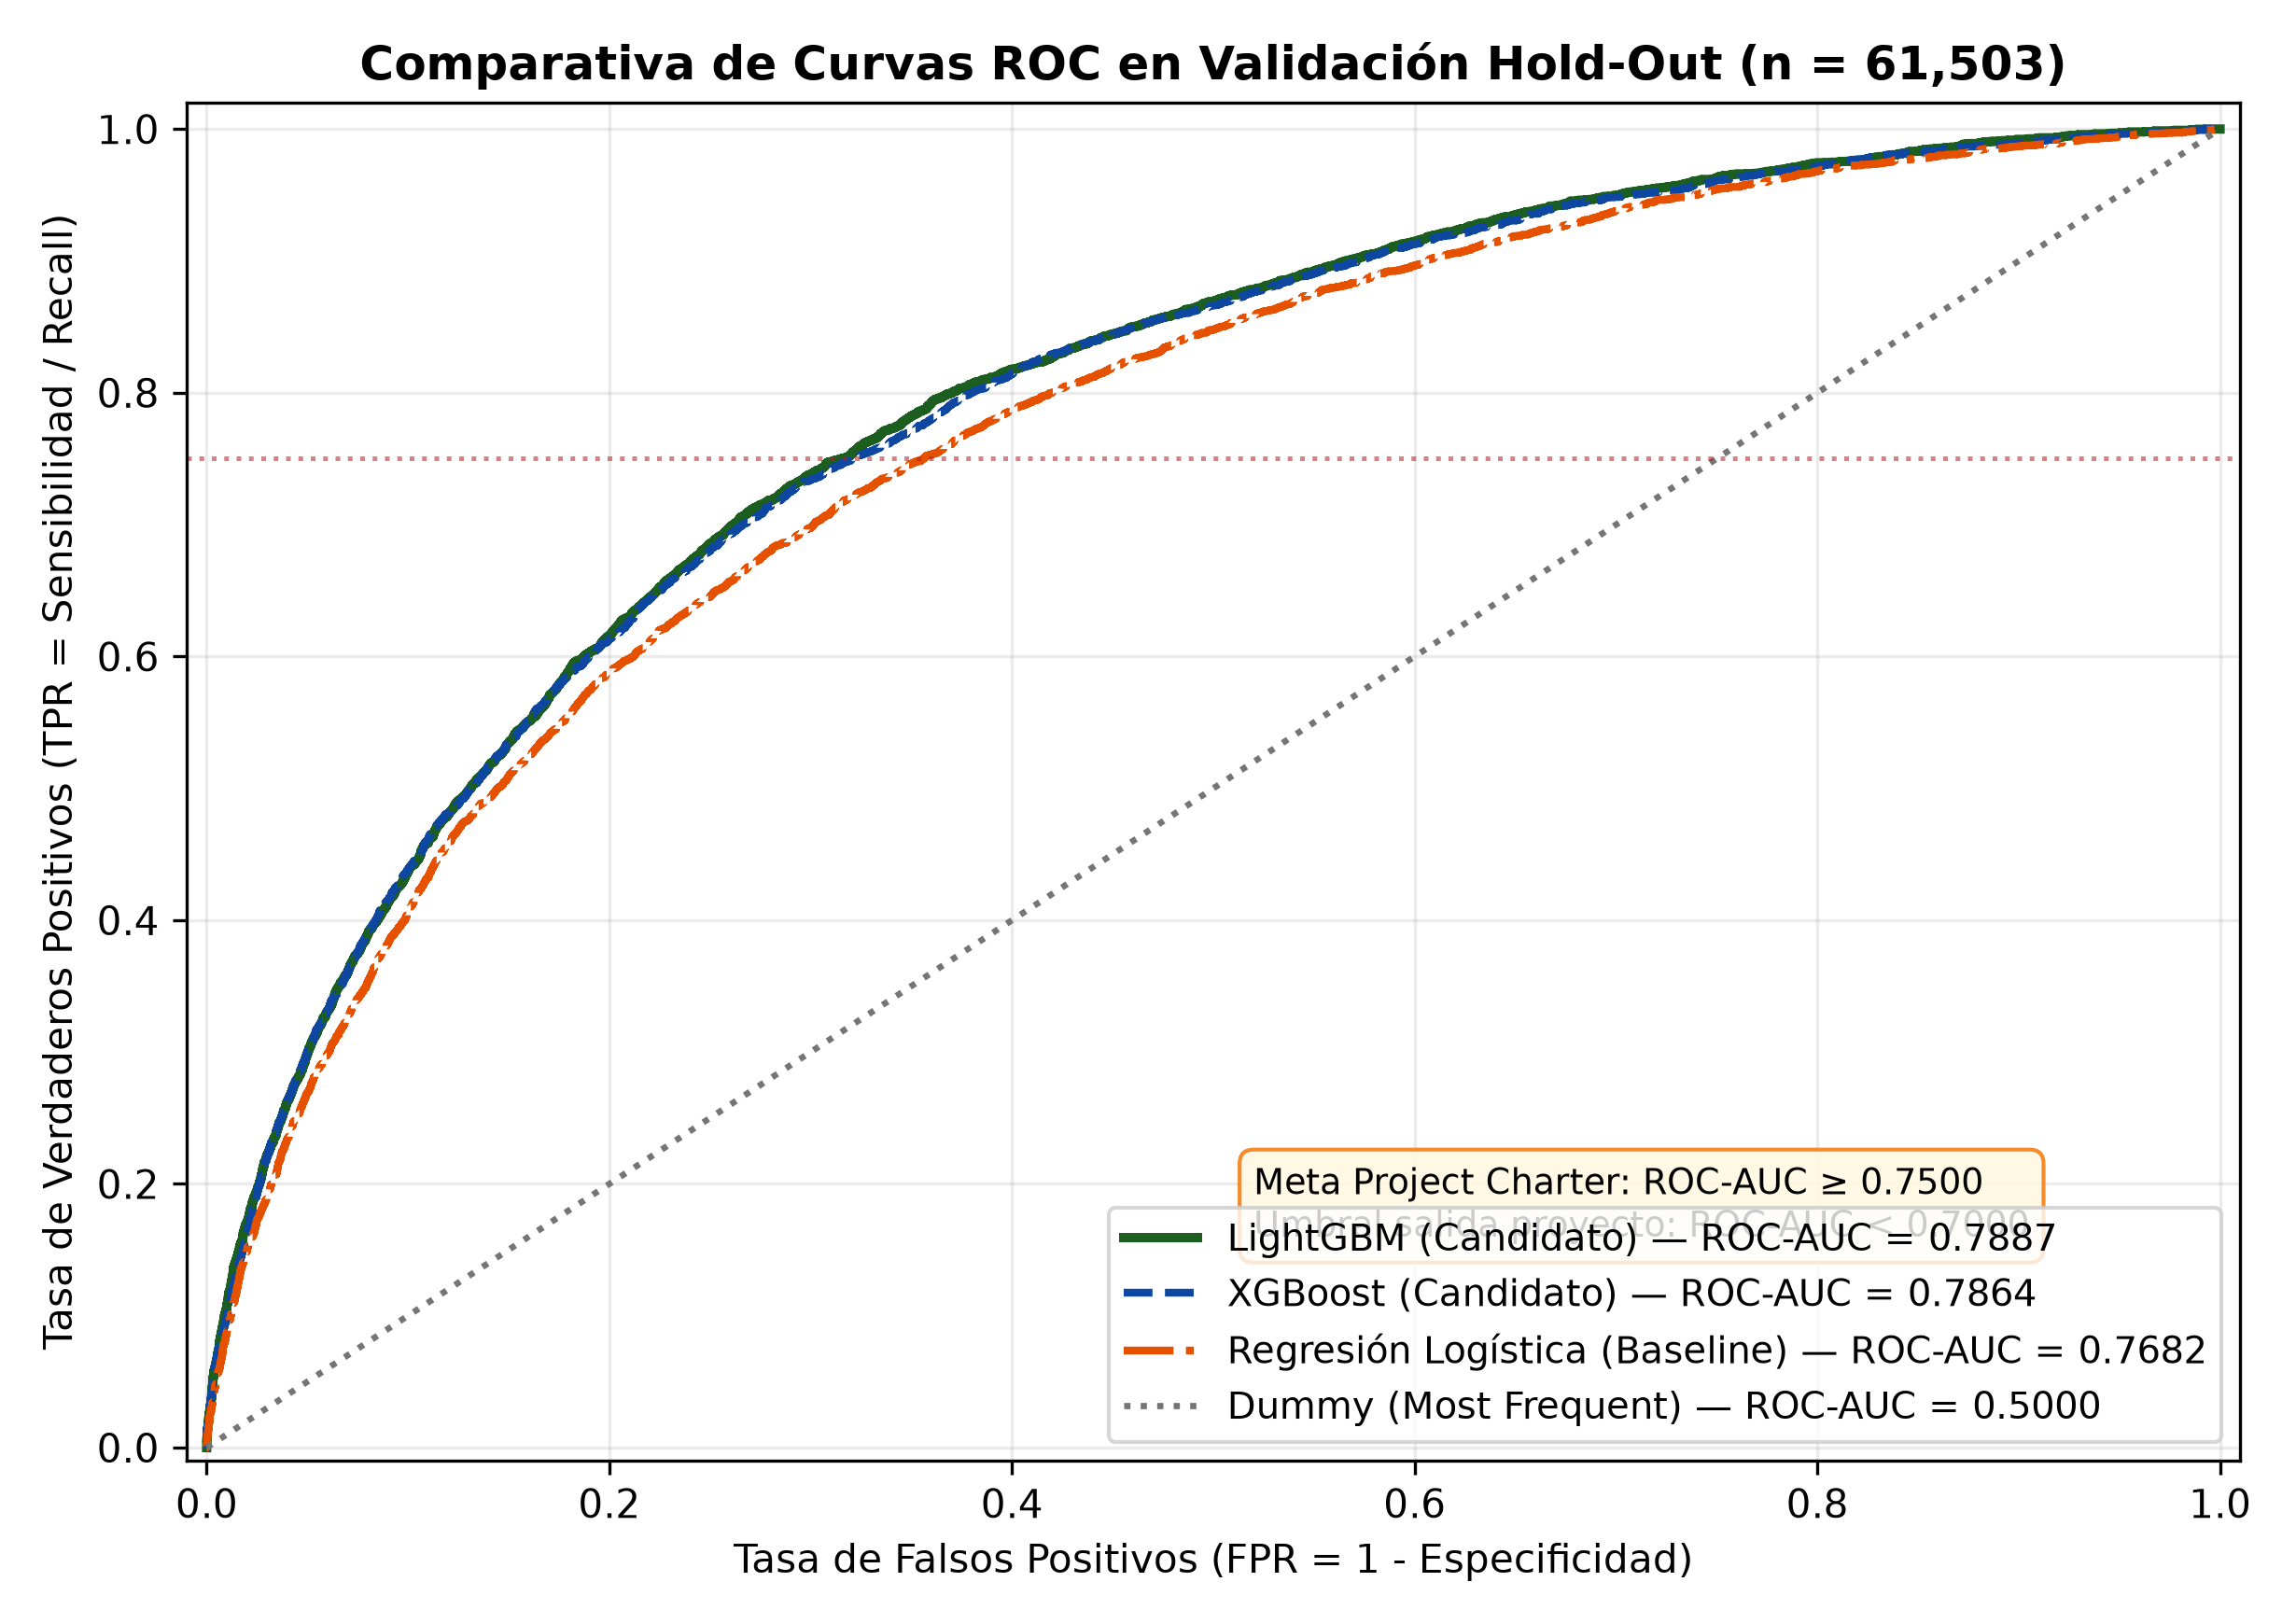

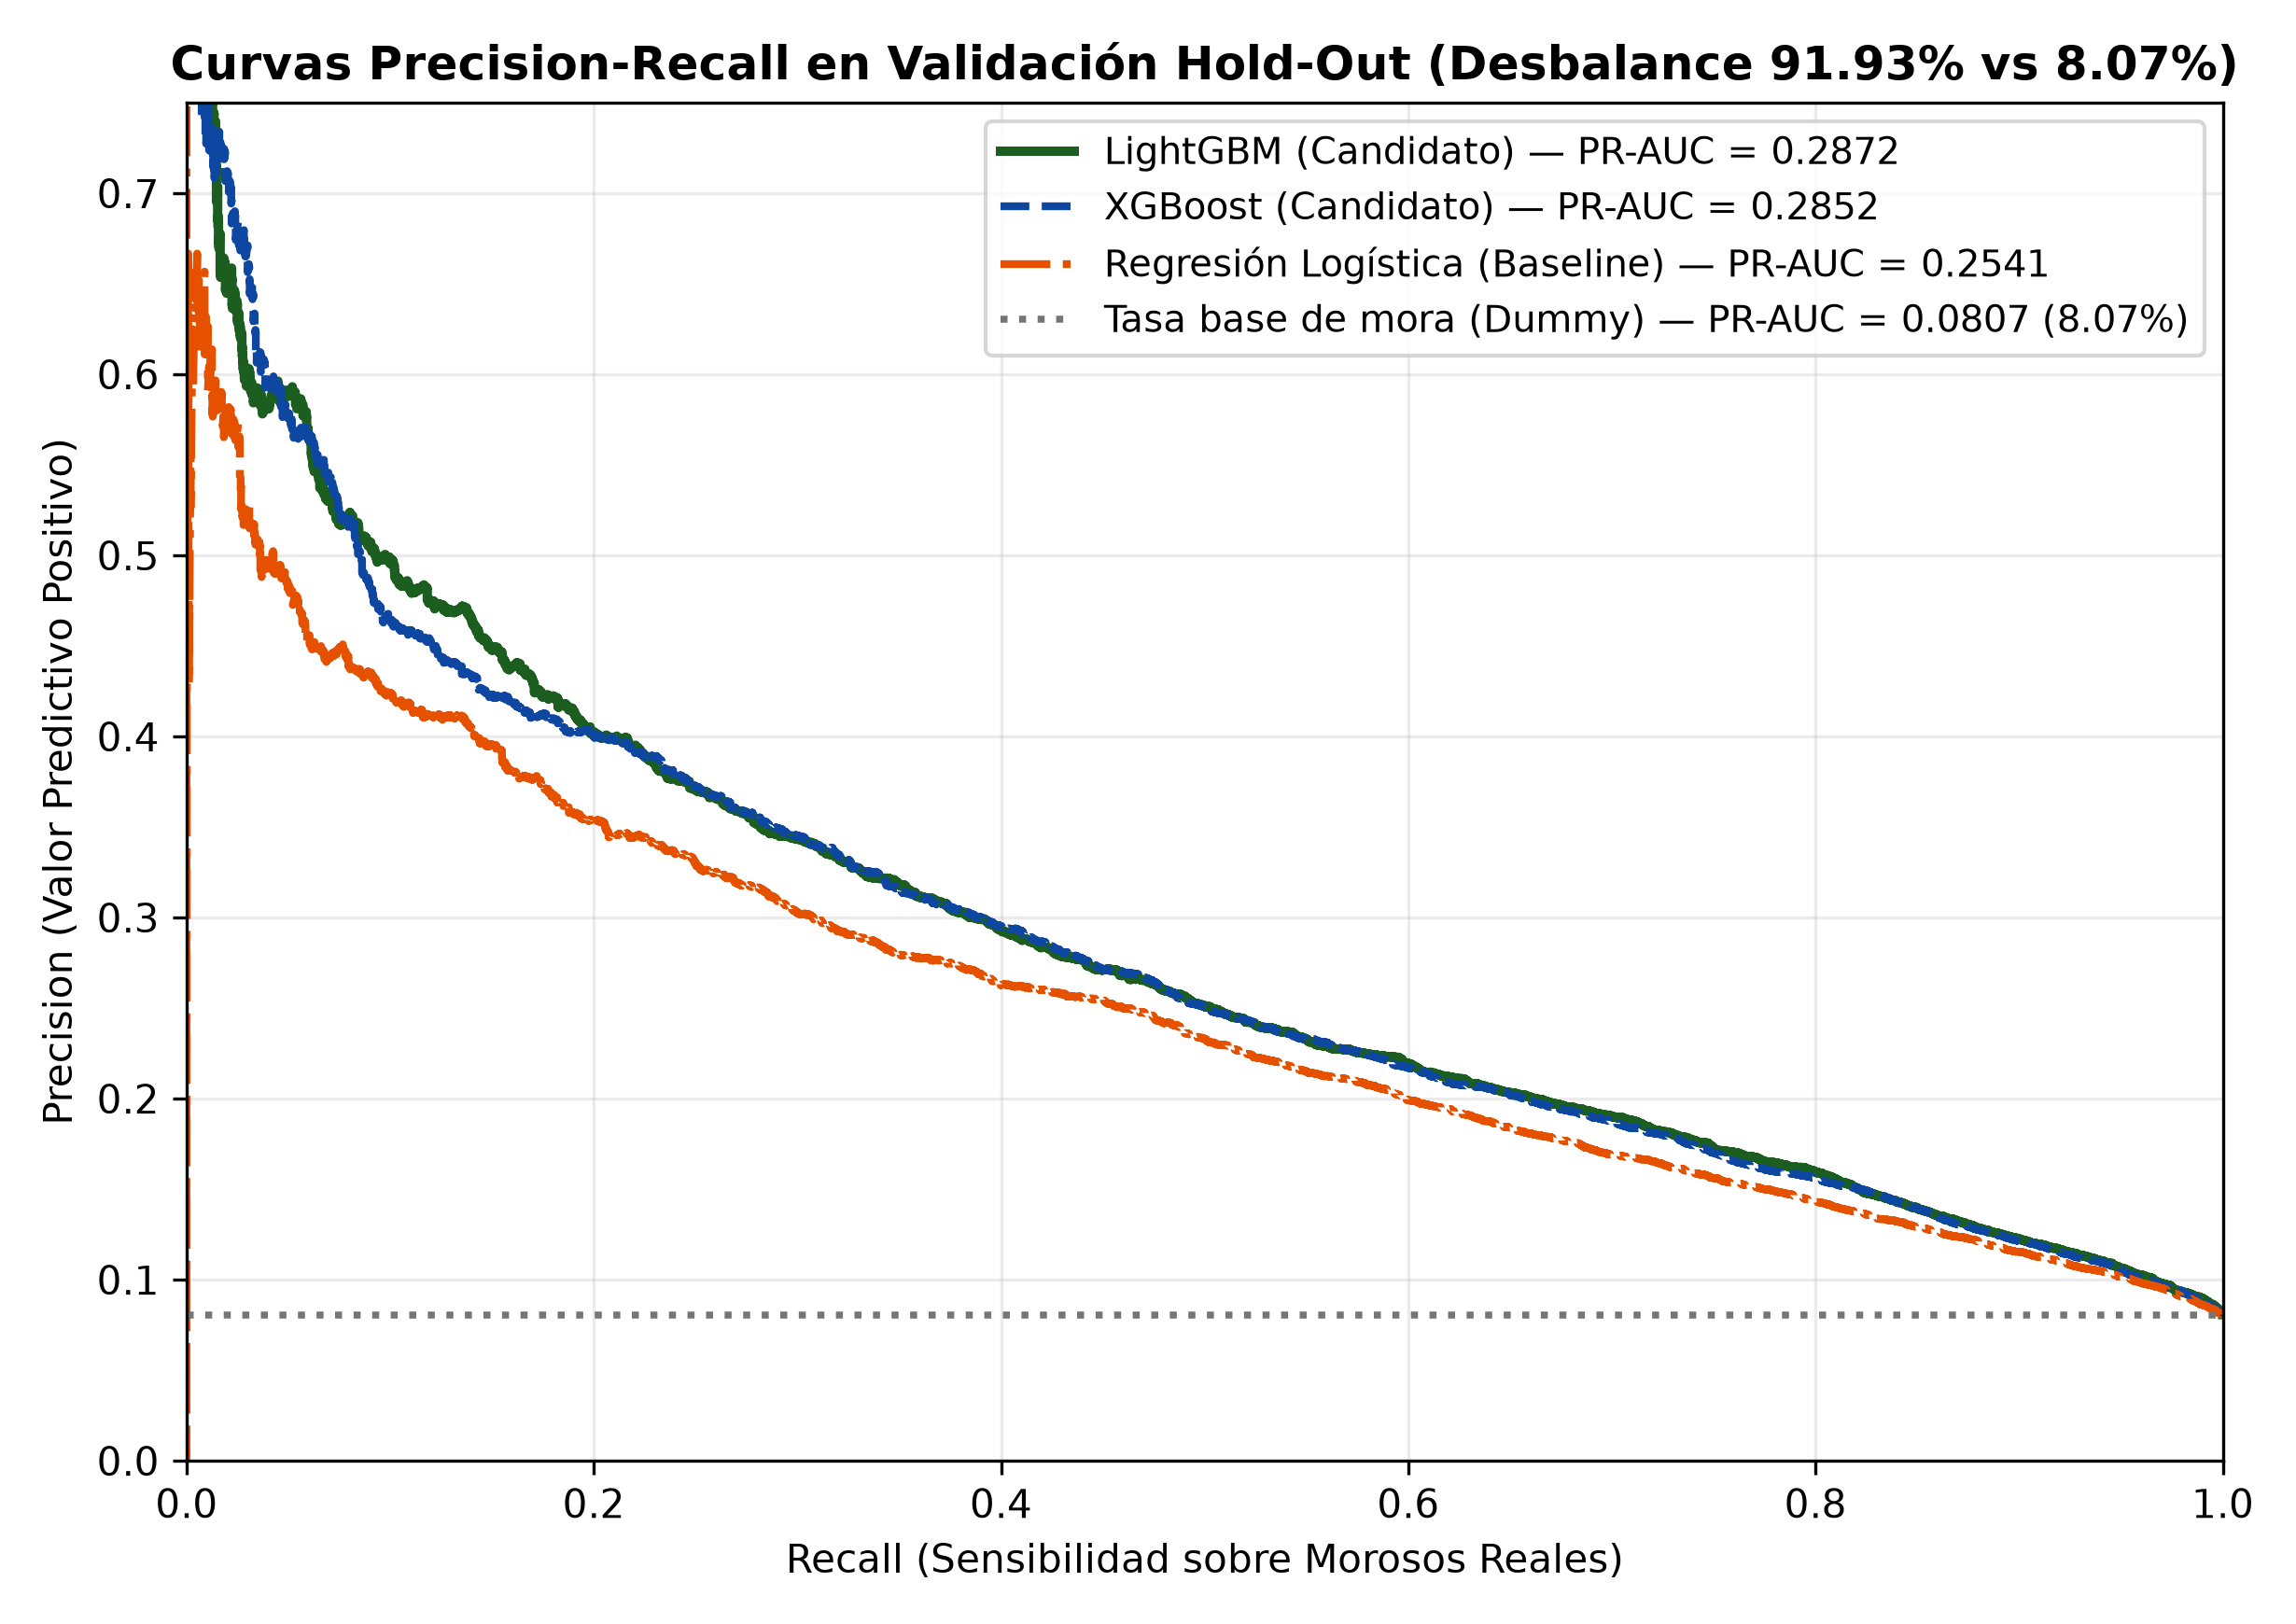

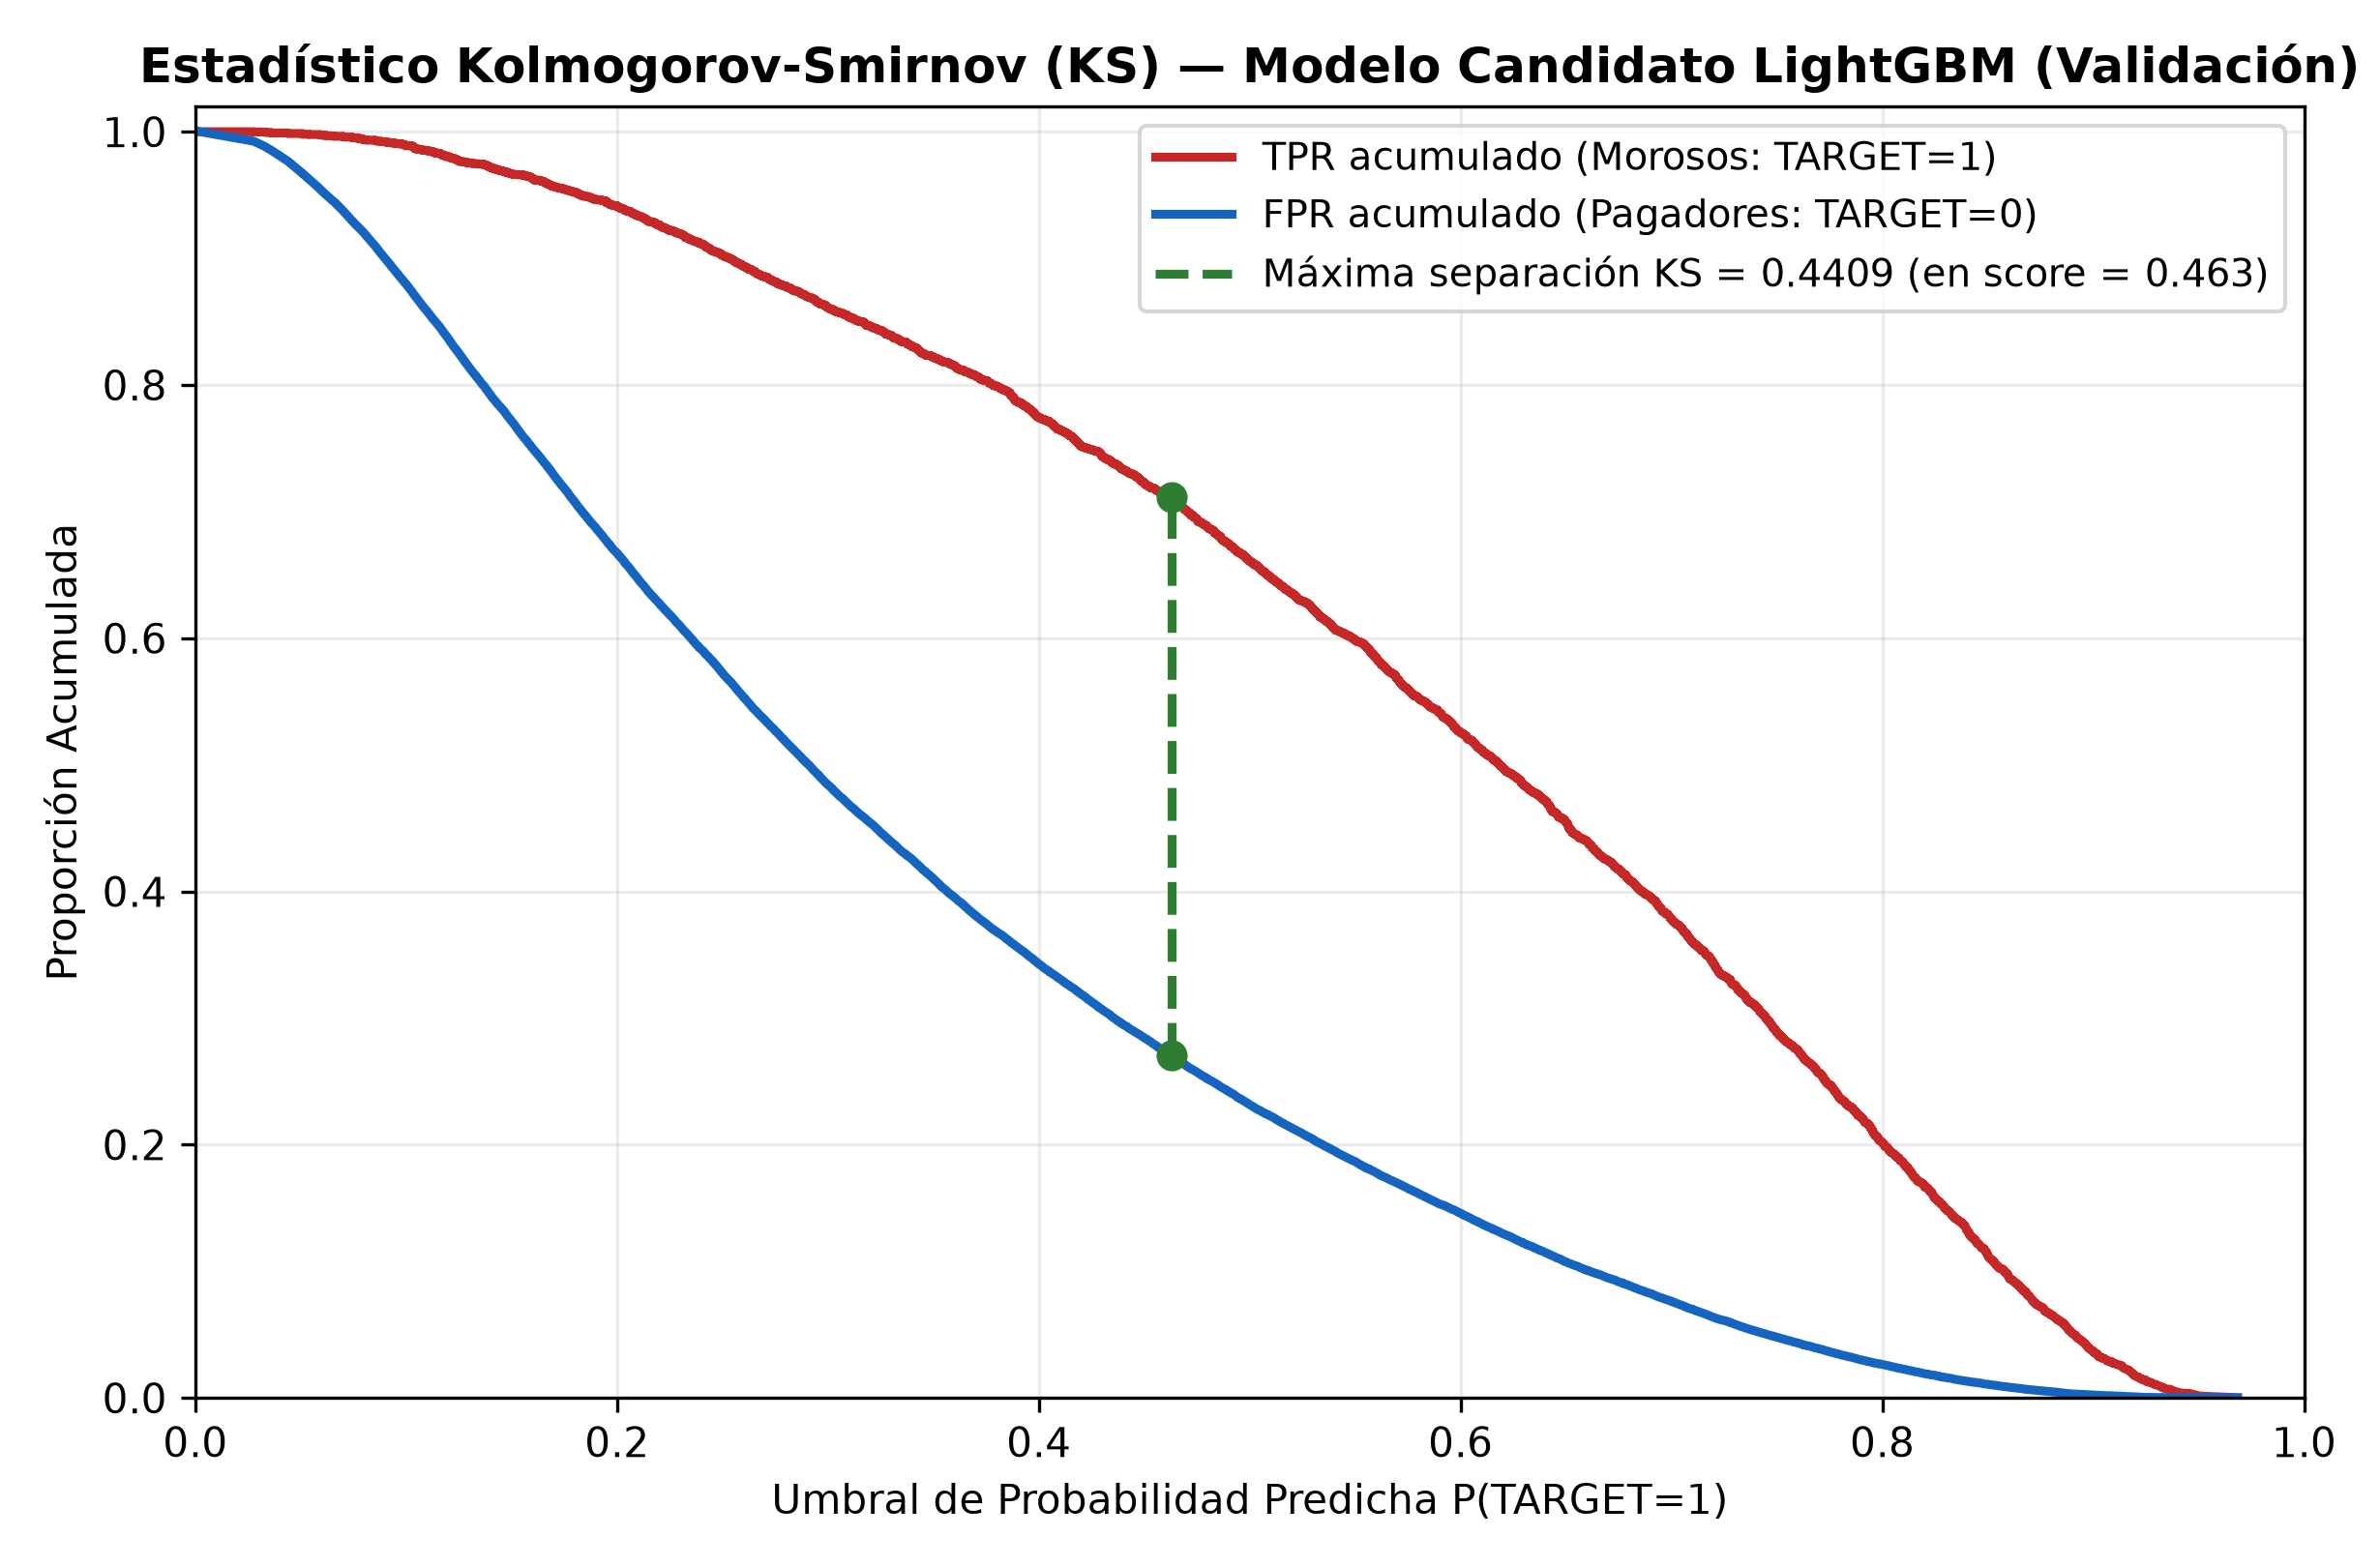

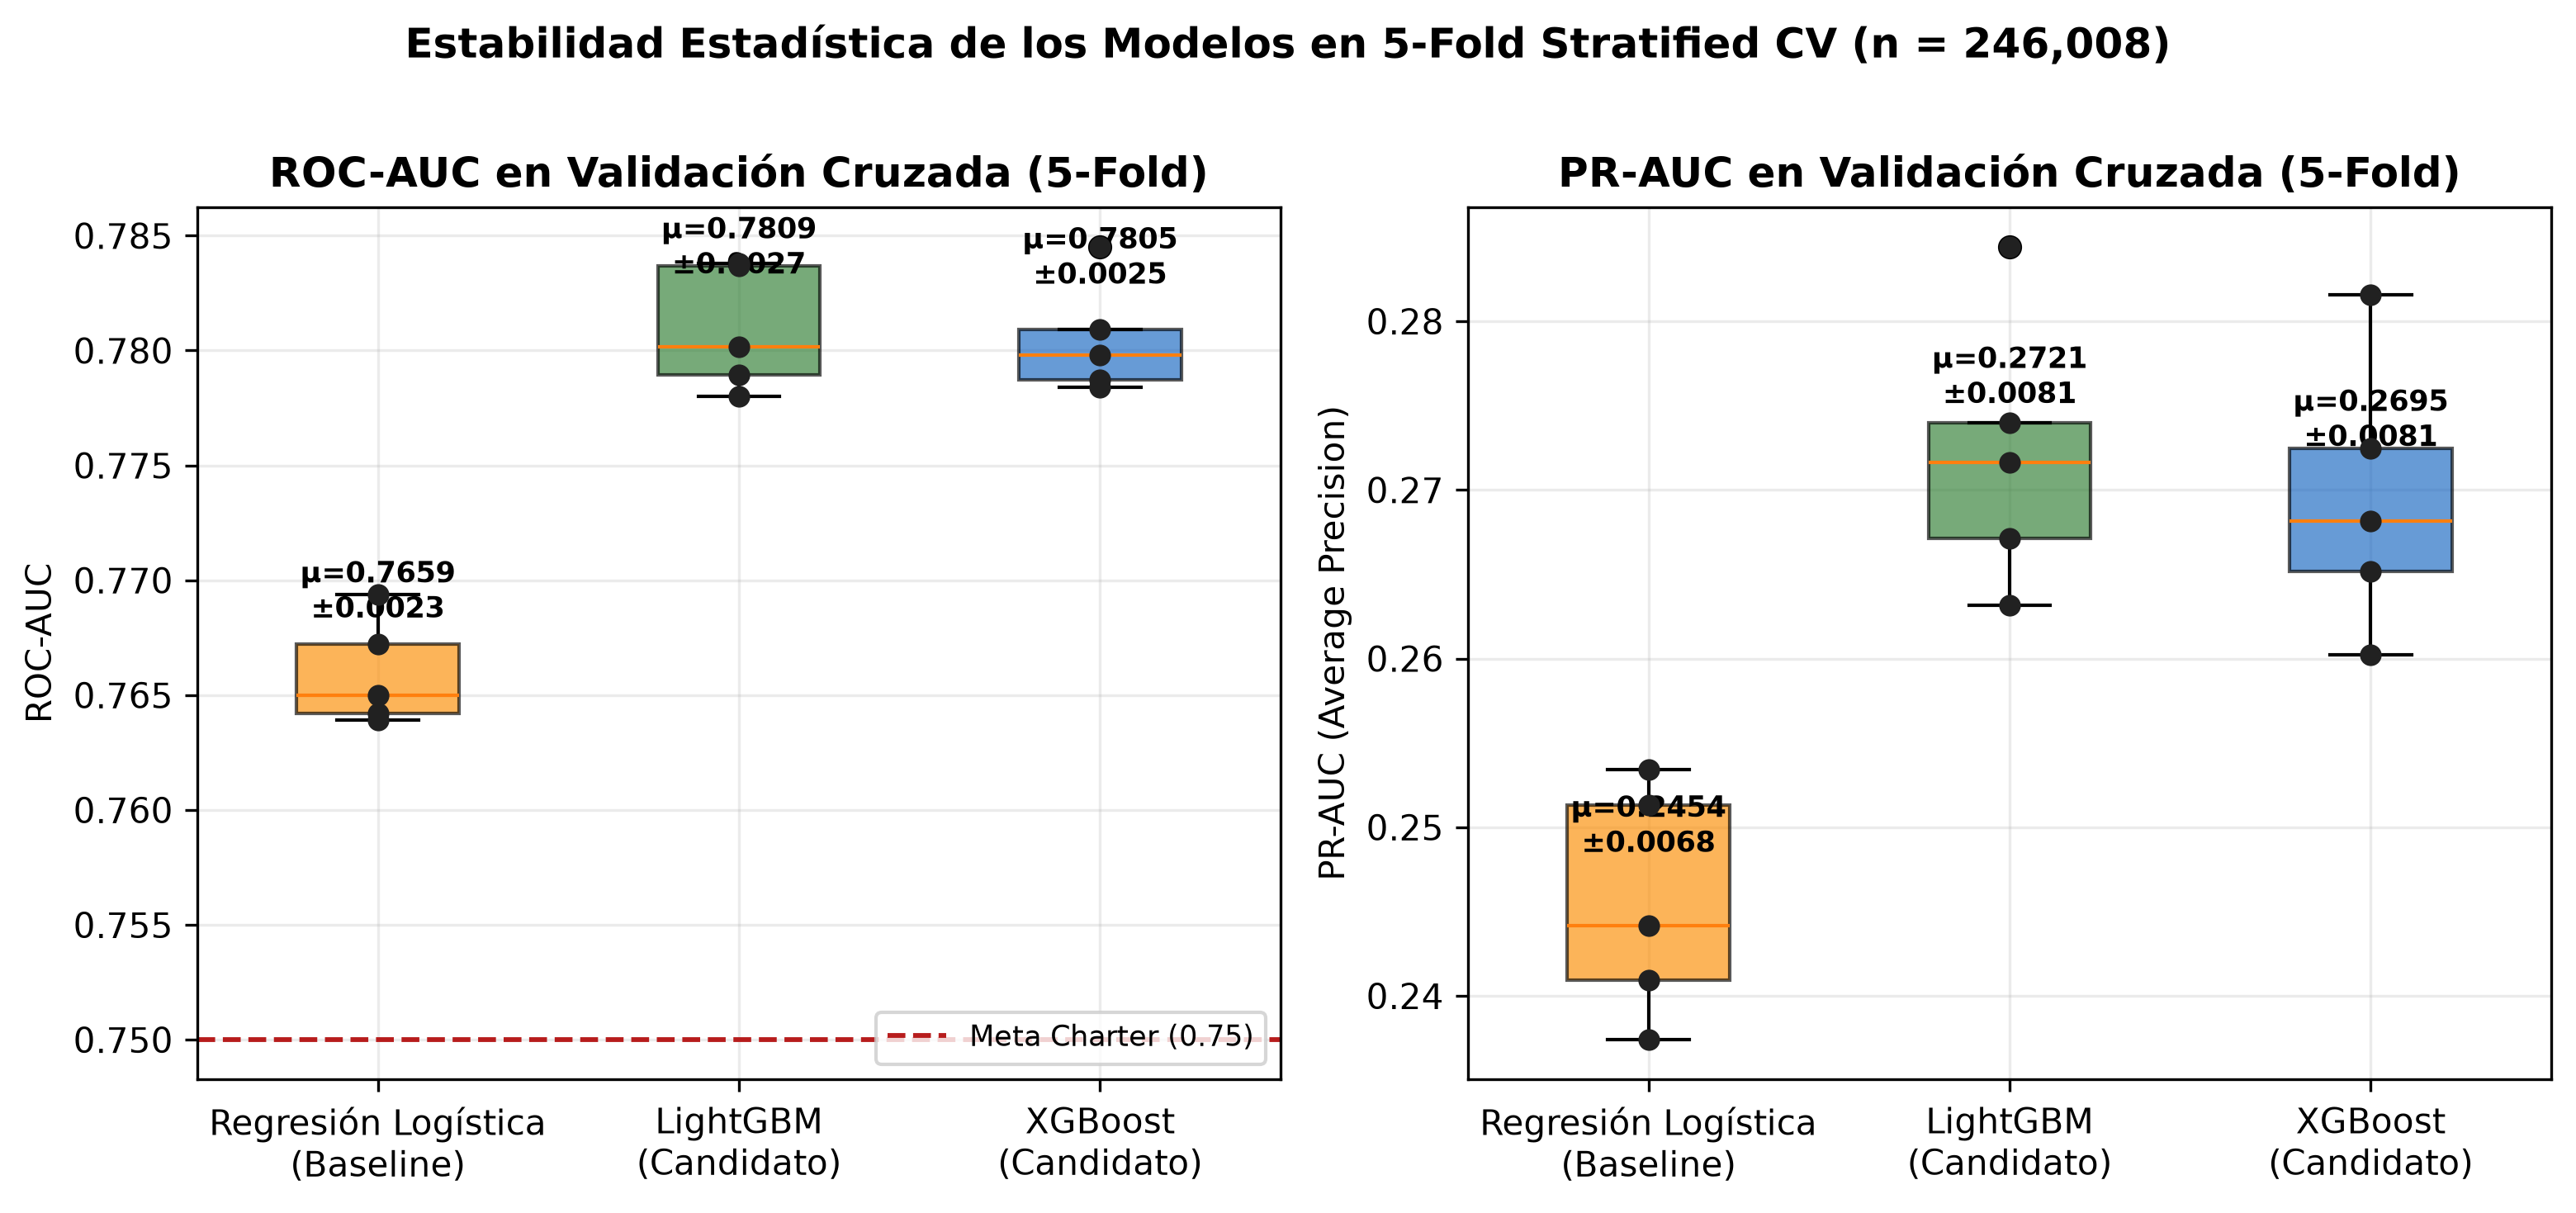

In [6]:
for fig_name in [
    'F01_curvas_roc_comparativa.png',
    'F02_curvas_pr_comparativa.png',
    'F03_curva_ks_lgbm.png',
    'F04_boxplots_cv5fold.png',
    'F07_curvas_calibracion_brier.png',
]:
    display(Image(filename=str(FIG_DIR / fig_name), width=780))

## 6. Patrones Predictivos Extraídos e Importancia de Variables por Familia Relacional
Se analiza la contribución porcentual a la ganancia de información (*Gain*) de las 8 familias de variables y el Top-25 de atributos más determinantes del modelo ganador `LightGBM`.

=== Importancia Agrupada por Familia Relacional (LightGBM) ===


,familia,n_variables,gain_pct_total,split_pct_total,top_variable
0,Scores Externos (EXT_SOURCE),10,31.45,10.21,EXT_SOURCE_MEAN
1,"Demográficas, Empleo y Estabilidad",53,20.77,26.78,ORGANIZATION_TYPE
2,Solicitudes Previas y POS_CASH,32,10.98,15.15,PREV_CNT_PAYMENT_MEAN
3,Buró Externo (bureau + balance),35,10.31,14.65,BUREAU_DEBT_RATIO_MEAN
4,Ratios Financieros y Montos,11,9.95,10.91,ANNUITY_TO_CREDIT_RATIO
5,Pagos de Cuotas (installments),16,8.15,9.53,INST_LATE_RATIO
6,Vivienda y Banderas de Ausencia,68,4.78,8.77,TOTALAREA_MODE
7,Tarjeta de Crédito (credit_card),15,3.62,4.01,CC_UTILIZATION_MAX


=== Top 20 Variables por Ganancia de Información (% Gain) ===


,variable,familia,gain,gain_pct,split,split_pct,ranking_gain
0,EXT_SOURCE_MEAN,Scores Externos (EXT_SOURCE),547841.2398,17.7036,389,1.4133,1
1,ORGANIZATION_TYPE,"Demográficas, Empleo y Estabilidad",265439.9484,8.5777,2848,10.3470,2
2,EXT_SOURCE_PROD,Scores Externos (EXT_SOURCE),194664.6172,6.2906,378,1.3733,3
3,ANNUITY_TO_CREDIT_RATIO,Ratios Financieros y Montos,96477.8108,3.1177,784,2.8483,4
4,OCCUPATION_TYPE,"Demográficas, Empleo y Estabilidad",75303.0077,2.4334,757,2.7502,5
5,CREDIT_TO_GOODS_RATIO,Ratios Financieros y Montos,54472.5244,1.7603,262,0.9519,6
6,BUREAU_DEBT_RATIO_MEAN,Buró Externo (bureau + balance),52658.2814,1.7017,282,1.0245,7
7,EXT_SOURCE_MAX,Scores Externos (EXT_SOURCE),50242.6225,1.6236,227,0.8247,8
8,EXT_SOURCE_MIN,Scores Externos (EXT_SOURCE),50204.7478,1.6224,302,1.0972,9
9,EXT_SOURCE_3,Scores Externos (EXT_SOURCE),44885.4671,1.4505,492,1.7875,10


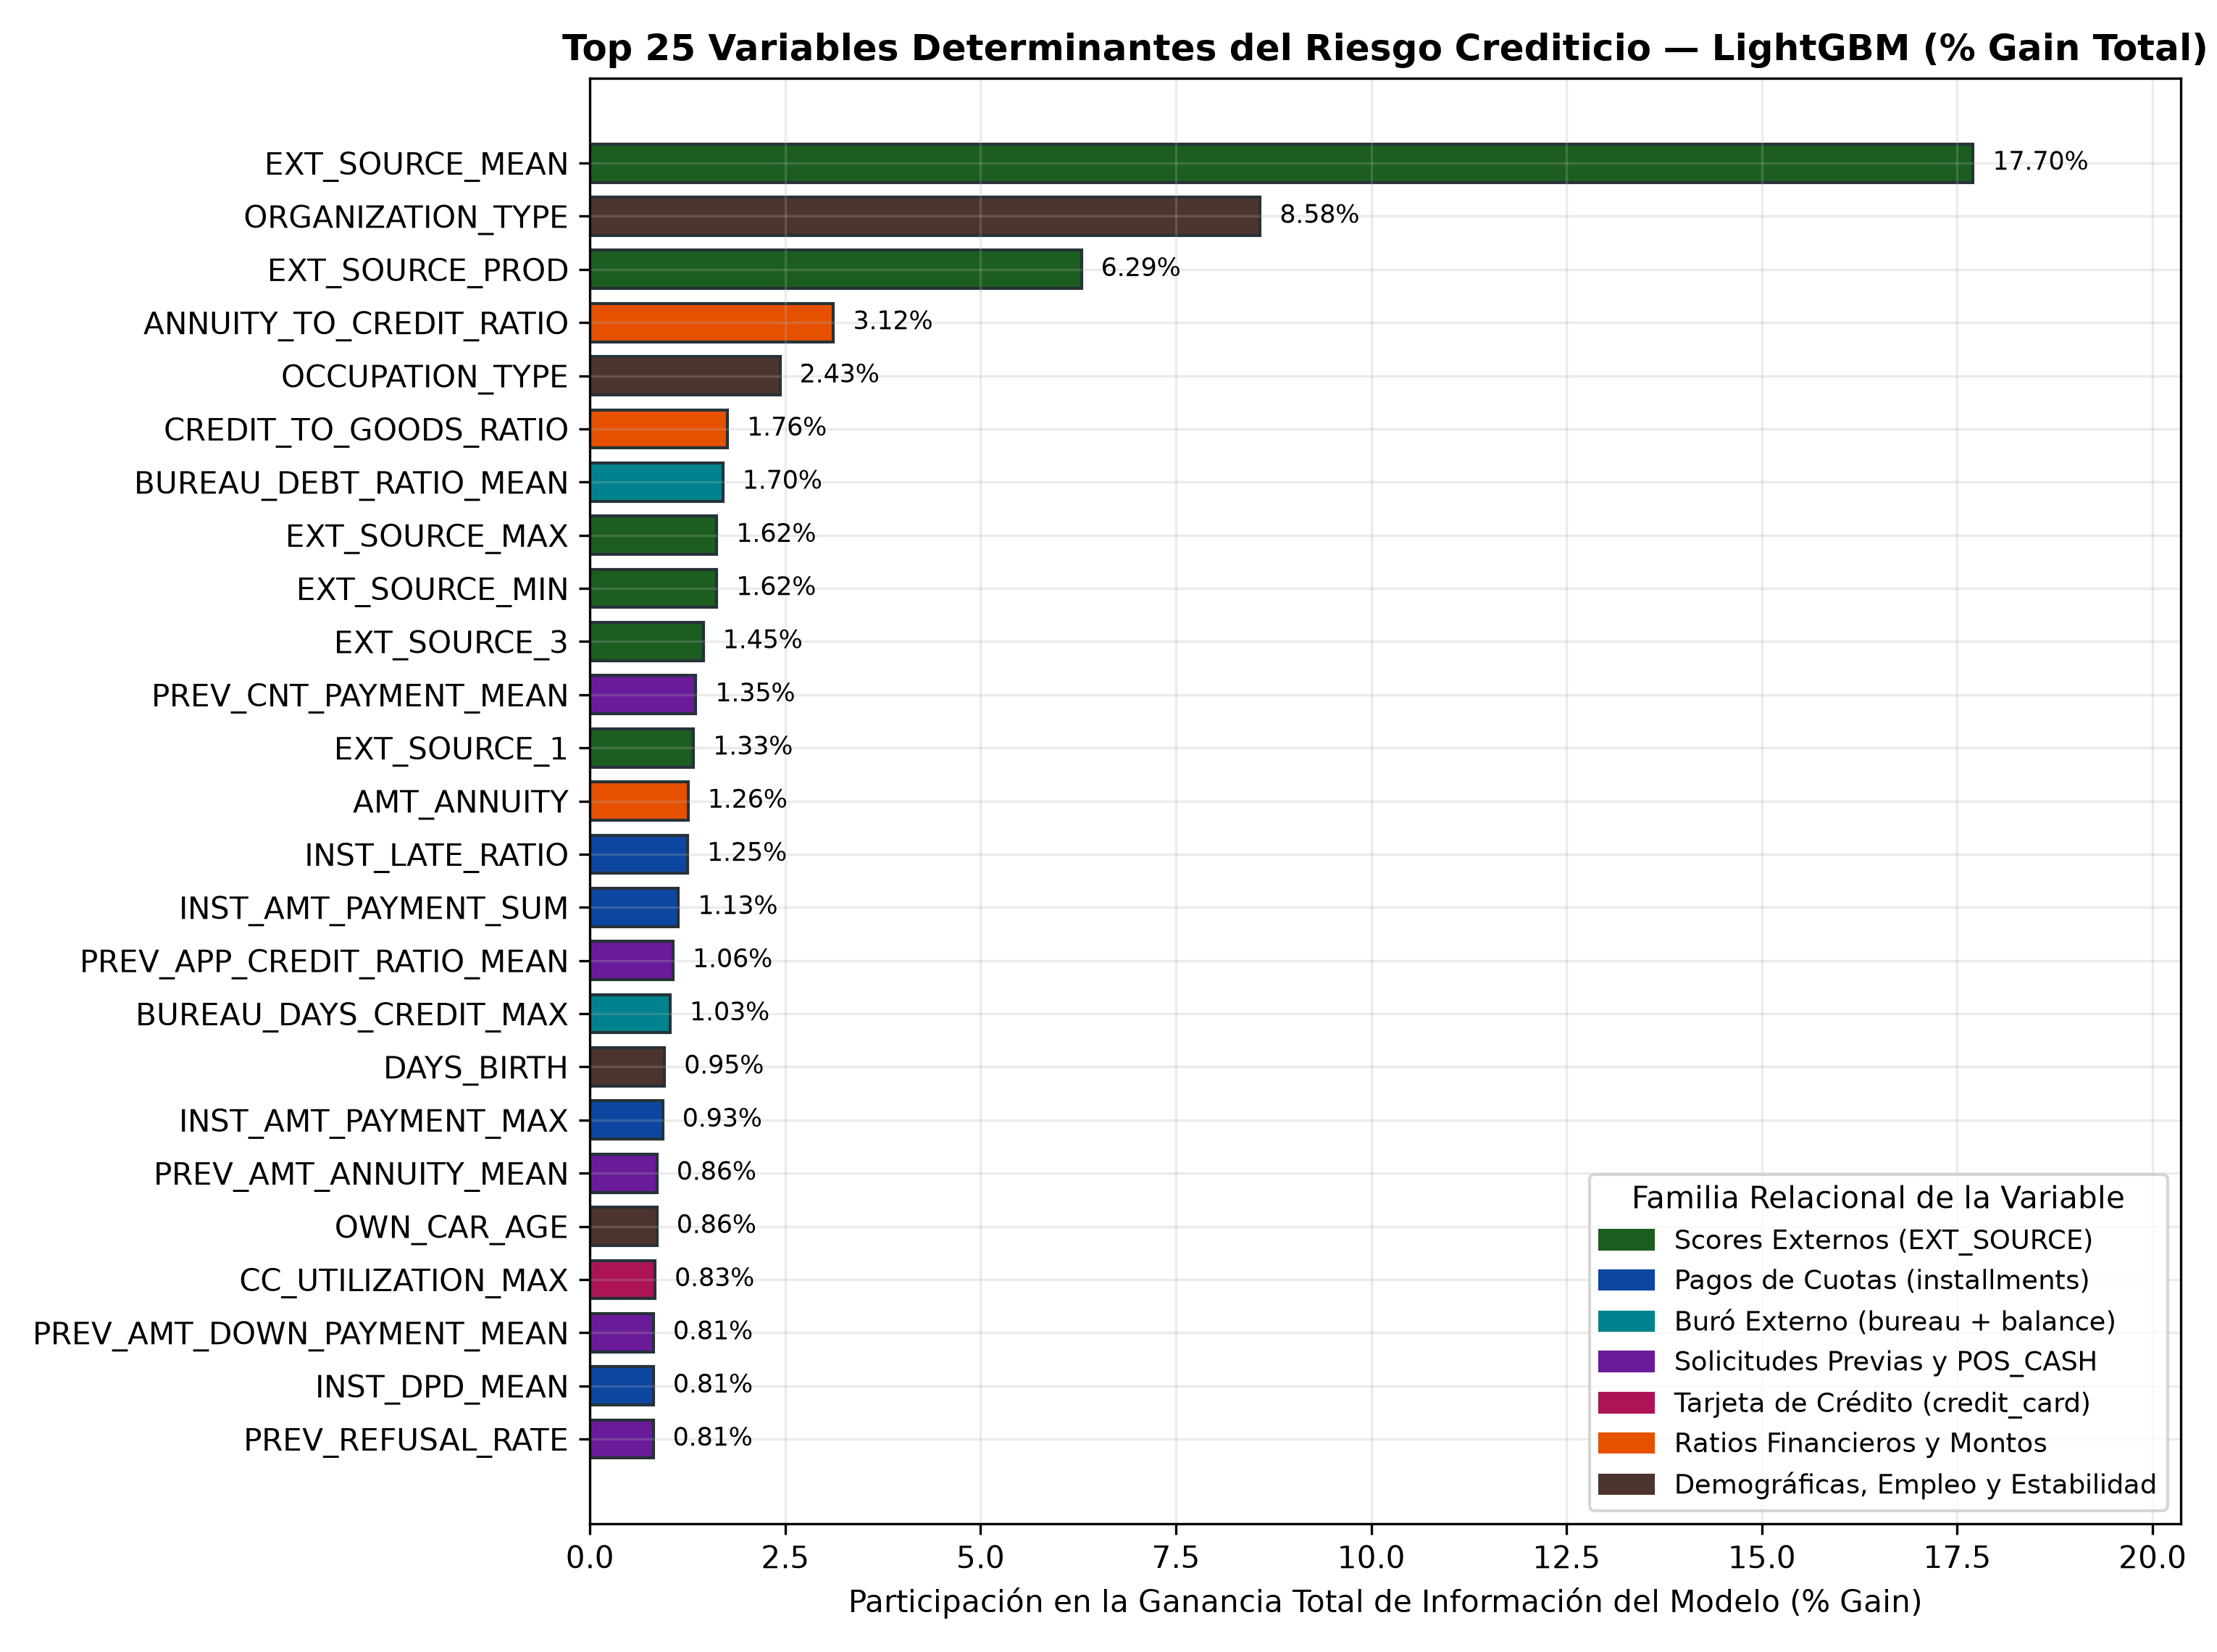

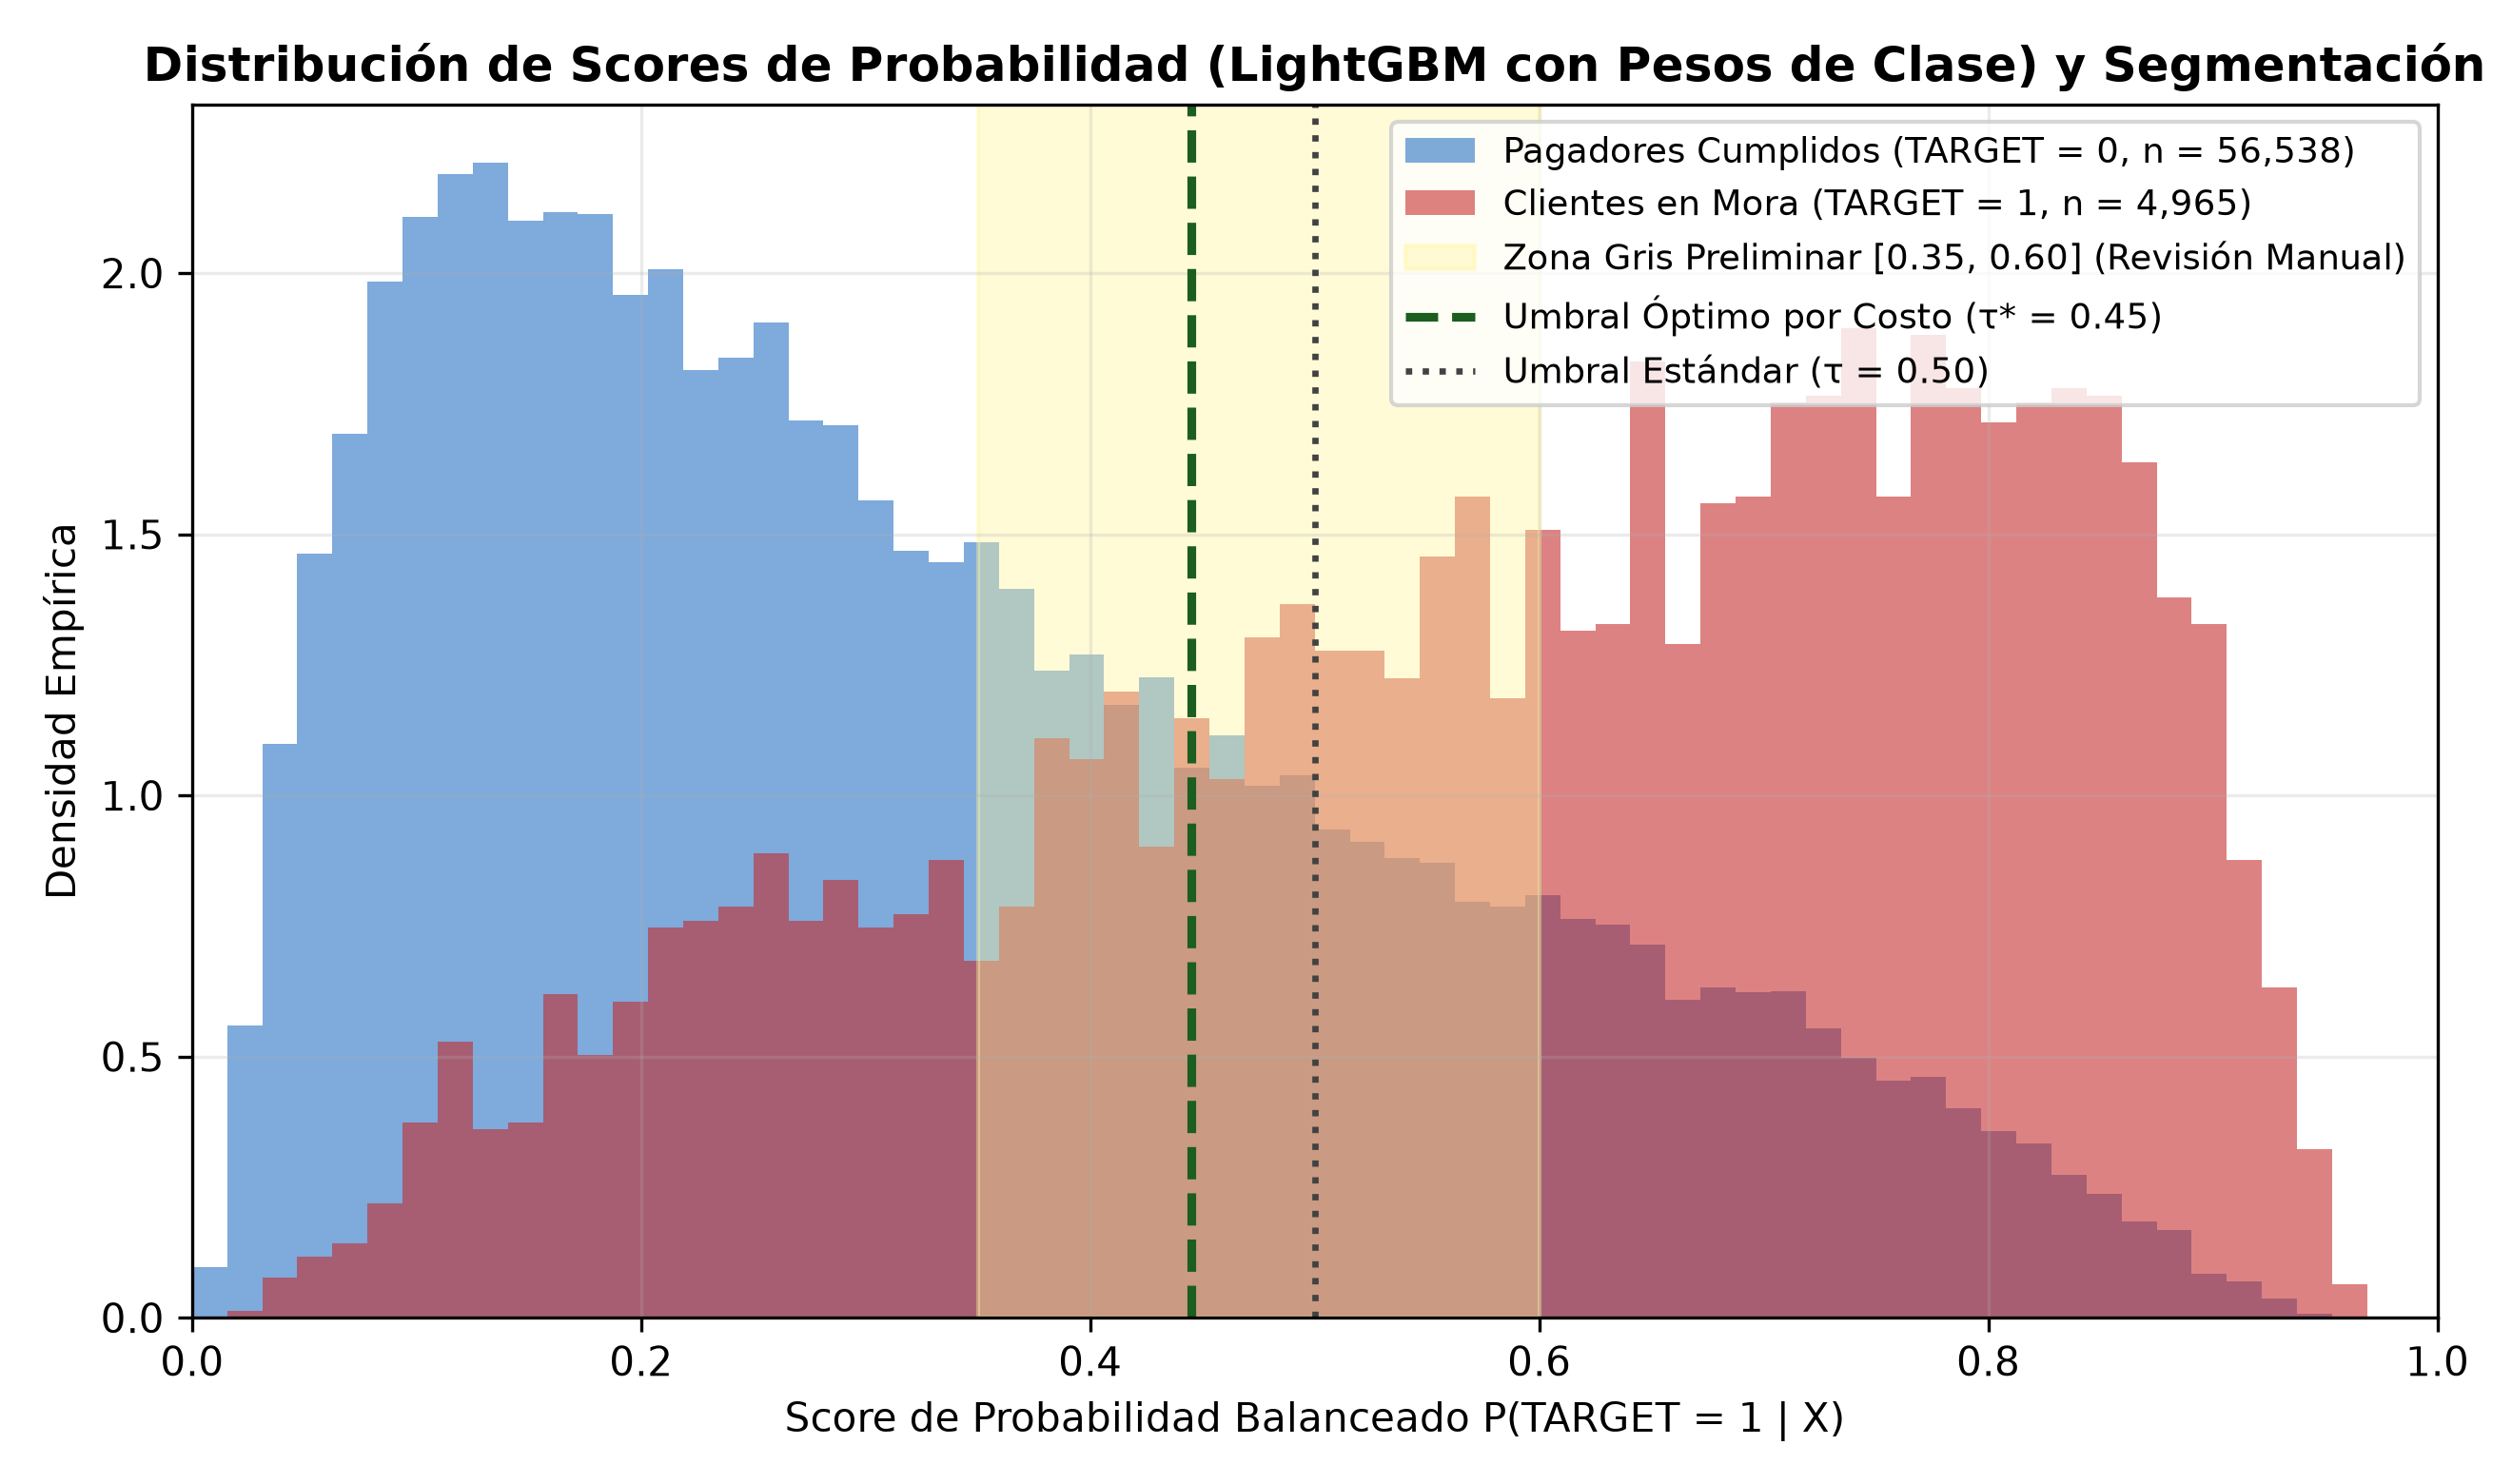

In [7]:
df_fam = pd.read_csv(TABLAS_DIR / 'importancia_por_familia_lgbm.csv')
df_imp_lgbm = pd.read_csv(TABLAS_DIR / 'feature_importance_lgbm.csv')
print('=== Importancia Agrupada por Familia Relacional (LightGBM) ===')
display(df_fam)
print('=== Top 20 Variables por Ganancia de Información (% Gain) ===')
display(df_imp_lgbm.head(20))
display(Image(filename=str(FIG_DIR / 'F05_importancia_variables_top25.png'), width=820))
display(Image(filename=str(FIG_DIR / 'F06_distribucion_scores_clases.png'), width=780))

## 7. Verificación del Prototipo del Servicio de Inferencia (`FastAPI` + `Docker` — Tareas F4.4 a F4.6)
Se inspecciona el diagrama de arquitectura y la prueba funcional de los endpoints `/health`, `/model/info`, `/predict` y `/predict/batch` sobre perfiles reales de validación.

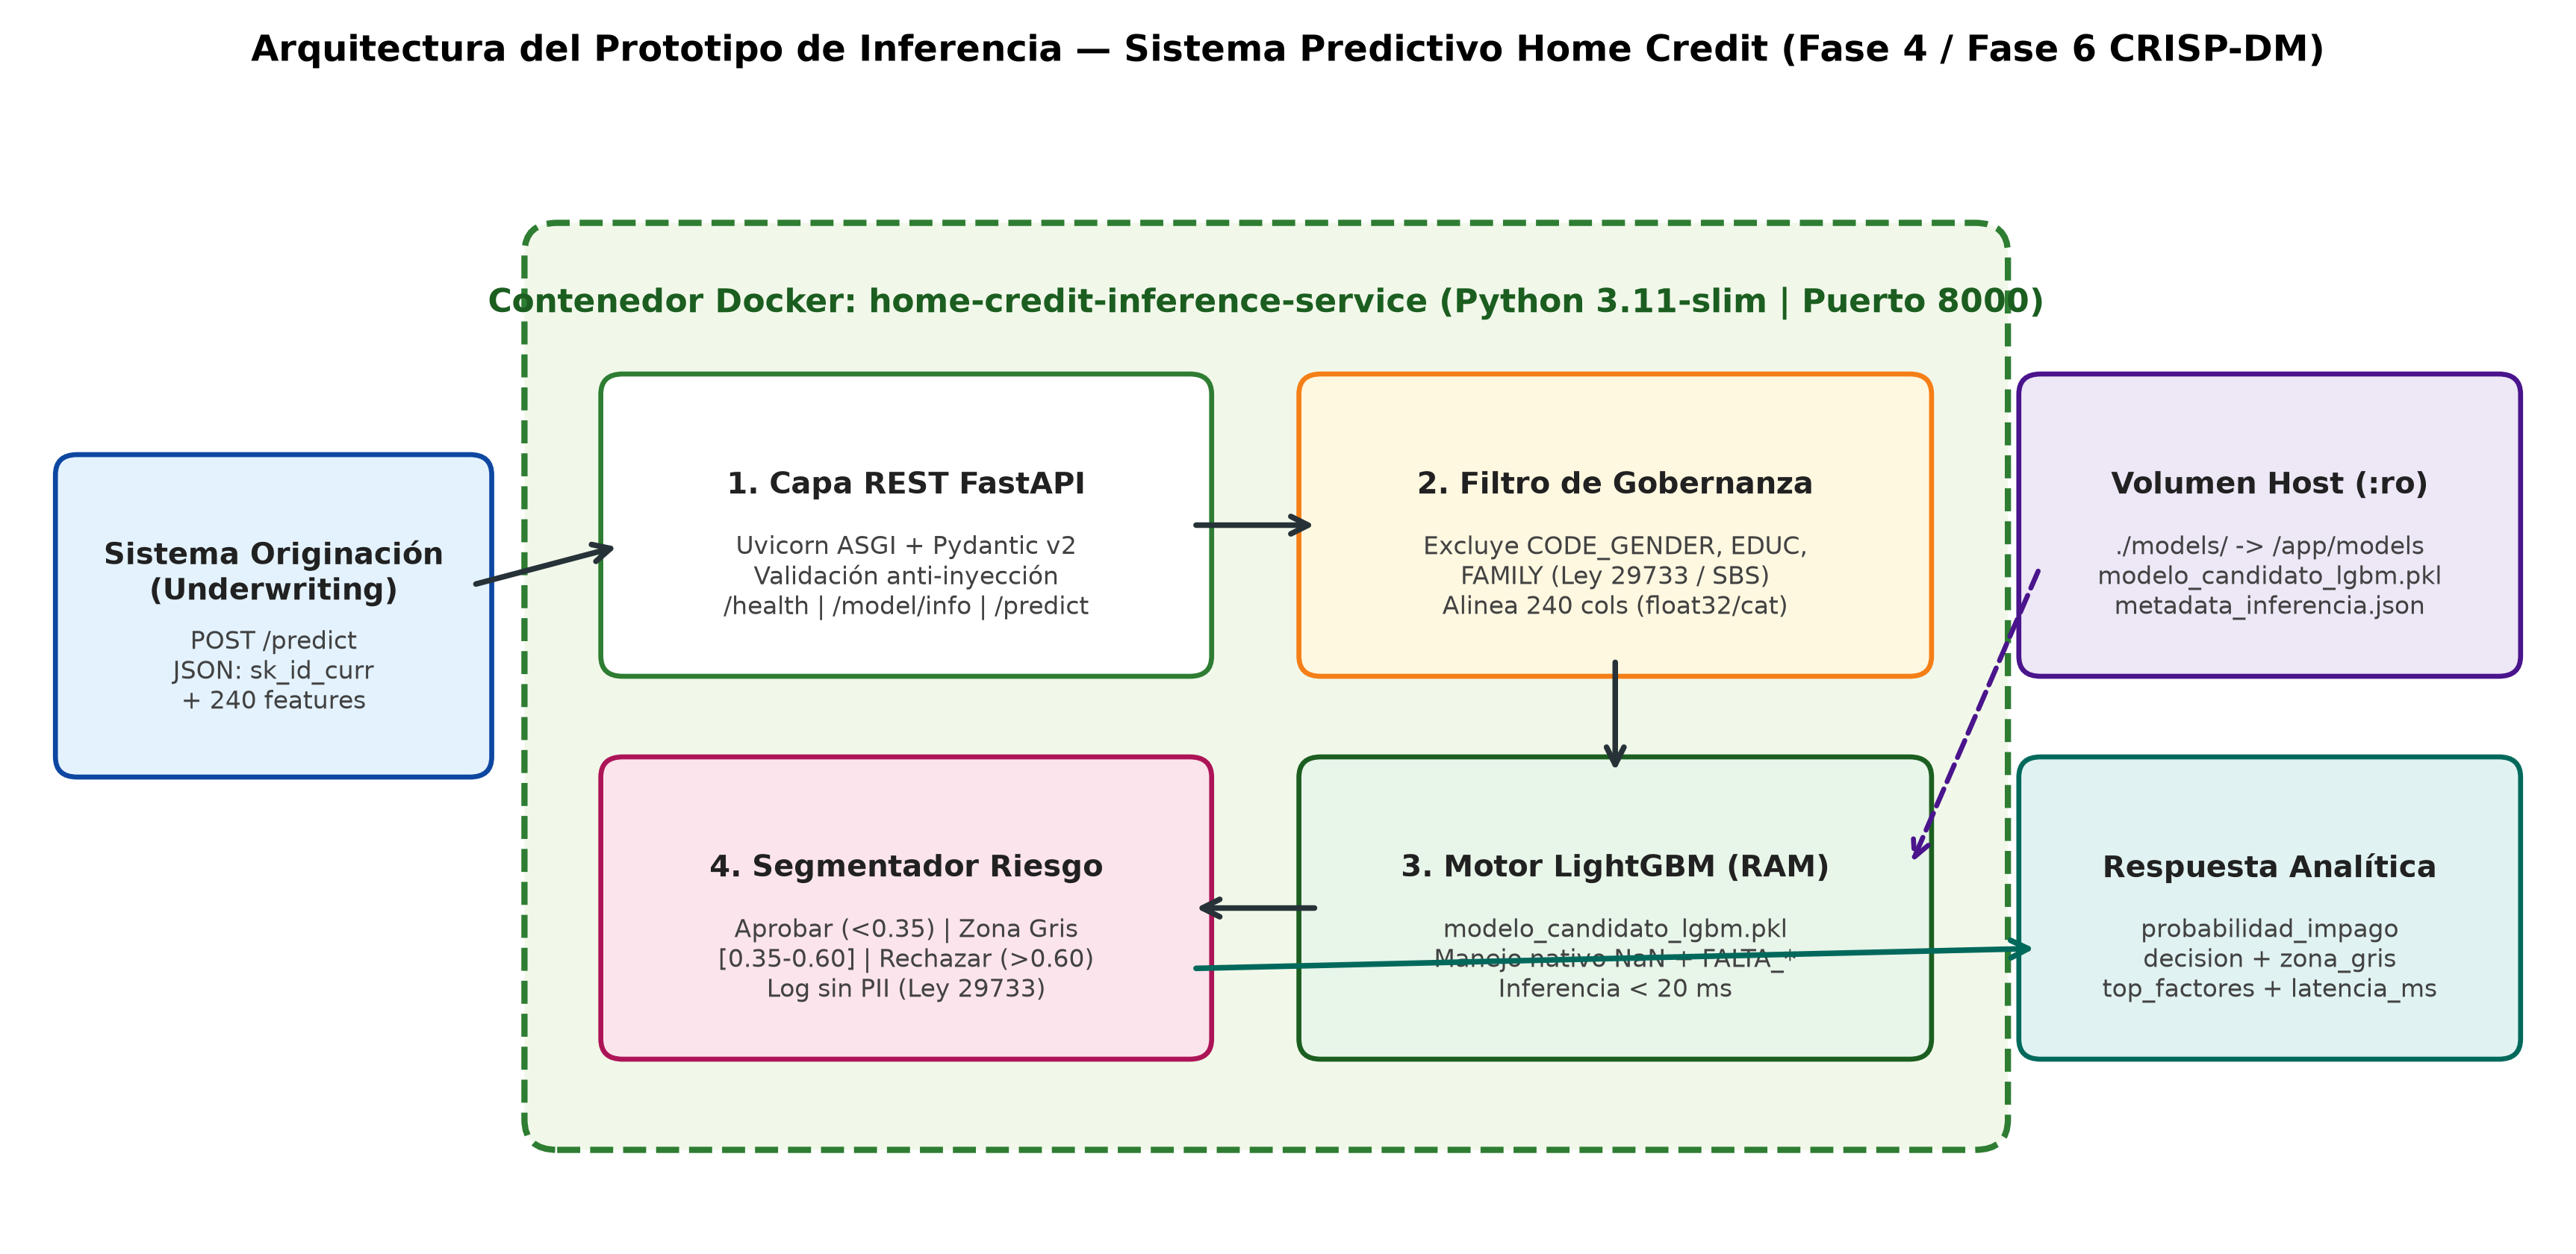

Estado /health: {'status': 'ok', 'service': 'home-credit-inference-service', 'phase': 'Fase 4 - Modelado (Borrador Funcional)', 'model_loaded': True, 'model_name': 'modelo_candidato_lgbm.pkl', 'loaded_at': '2026-11-15T18:58:48Z'}
Cobertura de Segmentación en Validación (Aprobación / Zona Gris / Rechazo):


,total_val_applicants,aprobar_automatico_pct,zona_gris_manual_pct,rechazar_automatico_pct,automatizacion_total_pct
0,61503,55.68,26.68,17.64,73.32


Predicciones individuales verificadas en /predict:


,perfil_prueba,sk_id_curr,target_real_val,probabilidad_impago,decision,requiere_revision_manual,latencia_ms
0,perfil_bajo_riesgo,433604,0,0.09204,APROBAR_AUTOMATICO,False,185.795
1,perfil_zona_gris,345558,0,0.43144,ZONA_GRIS_REVISION_MANUAL,True,326.915
2,perfil_alto_riesgo,218614,0,0.76057,RECHAZAR_AUTOMATICO,False,290.049


In [8]:
display(Image(filename=str(FIG_DIR / 'diagrama_arquitectura.png'), width=860))
with open(OUT_DIR / 'prueba_servicio_inferencia.json', encoding='utf-8') as f:
    prueba_api = json.load(f)
print('Estado /health:', prueba_api['health_endpoint'])
print('Cobertura de Segmentación en Validación (Aprobación / Zona Gris / Rechazo):')
display(pd.DataFrame([prueba_api['val_segmentation_coverage']]))
print('Predicciones individuales verificadas en /predict:')
display(pd.DataFrame(prueba_api['single_predictions_verified'])[['perfil_prueba', 'sk_id_curr', 'target_real_val', 'probabilidad_impago', 'decision', 'requiere_revision_manual', 'latencia_ms']])